In [ ]:
import requests
import pandas as pd

BASE_URL = "http://www.bom.gov.au/waterdata/services"
HEADERS = {"User-Agent": "wa-water-pipeline (portfolio project; chaoyue0224@gmail.com)"}

def kiwis(request, **params):
    base = {"service": "kisters", "type": "queryServices",
            "datasource": 0, "format": "json", "request": request}
    r = requests.get(BASE_URL, params={**base, **params}, headers=HEADERS, timeout=60)
    r.raise_for_status()
    return r.json()

def to_df(data):
    # KiWIS list responses are [header_row, row, row, ...]
    return pd.DataFrame(data[1:], columns=data[0])

stations = to_df(kiwis(
    "getStationList",
    returnfields="station_name,station_no,station_id,station_latitude,station_longitude",
))
print(len(stations))
stations.head()

139880


,station_name,station_no,station_id,station_latitude,station_longitude
0,"""Warrington"" Wingadee No2",GW004619,643996,,
1,# 10,80210426,12803776,-18.939196923,125.657530577
2,# 6 Panoroma,80210364,12857268,-18.612078506,125.48035847
3,# 7,80210365,12803712,-18.549837342,125.31596001
4,# 8,80210385,12803732,-18.424066757,125.44320633


In [3]:
for col in ["station_latitude", "station_longitude"]:
    stations[col] = pd.to_numeric(stations[col], errors="coerce")

sw_wa = stations[
    stations["station_latitude"].between(-35.2, -30.5)
    & stations["station_longitude"].between(114.8, 118.5)
]
print(len(sw_wa))
sw_wa.head(20)

40456


,station_name,station_no,station_id,station_latitude,station_longitude
5,#1,61402892,11583465,-32.189546,115.938500
6,#1,61310955,11452685,-32.793279,115.650347
7,#10,61310965,11452725,-32.766671,115.629601
8,#11,61310966,11452729,-32.766379,115.633374
9,#12,61310967,11452733,-32.766349,115.635617
10,#13 East,61310968,11452737,-32.766429,115.638007
11,#13 West,61310969,11452741,-32.766438,115.637974
12,#14,61310970,11452745,-32.771330,115.639896
13,#15,61310971,11452749,-32.766381,115.648544
15,#16,61310972,11452753,-32.783756,115.652136


In [4]:
ts = to_df(kiwis(
    "getTimeseriesList",
    parametertype_name="Water Course Discharge",
    ts_name="DMQaQc.Merged.DailyMean.24HR",
    returnfields="station_no,station_name,ts_id,coverage",
))

candidates = ts[ts["station_no"].isin(sw_wa["station_no"])].copy()
candidates["from"] = pd.to_datetime(candidates["from"], errors="coerce", utc=True)
candidates["to"] = pd.to_datetime(candidates["to"], errors="coerce", utc=True)

long_records = candidates[
    (candidates["from"] < "1995-01-01")
    & (candidates["to"] > pd.Timestamp.now(tz="UTC") - pd.Timedelta(days=60))
].sort_values("from")
long_records

,station_no,station_name,ts_id,from,to
727,614044,Yarragil Formation,99145010,1951-08-21 16:00:00+00:00,2026-10-22 16:00:00+00:00
2111,608151,Strickland,82216010,1951-12-30 16:00:00+00:00,2026-10-23 16:00:00+00:00
2041,605012,Mount Frankland,78933010,1951-12-31 16:00:00+00:00,2026-10-23 16:00:00+00:00
1844,611026,Dowdells Rd Bridge,92214010,1952-01-02 16:00:00+00:00,2026-10-22 16:00:00+00:00
1878,614006,Baden Powell,97444010,1952-01-21 16:00:00+00:00,2026-10-22 16:00:00+00:00
...,...,...,...,...,...
1705,602014,Billa Boya Reserve,75523010,1991-12-31 16:00:00+00:00,2026-10-22 16:00:00+00:00
2107,602015,Warren Rd,75569010,1992-05-05 16:00:00+00:00,2026-10-23 16:00:00+00:00
2113,602010,Robinson Dr Conflu,75408010,1992-05-05 16:00:00+00:00,2026-10-23 16:00:00+00:00
2106,602009,Drop Structure,75363010,1993-02-21 16:00:00+00:00,2026-10-23 16:00:00+00:00


In [5]:
import json, time, pathlib

RAW = pathlib.Path("data/raw/bom_daily"); RAW.mkdir(parents=True, exist_ok=True)
START, END = "1975-01-01", "2026-09-30"

def get_daily(ts_id):
    f = RAW / f"{ts_id}.json"
    if f.exists():
        v = json.loads(f.read_text())
    else:
        v = kiwis("getTimeseriesValues", ts_id=ts_id,
                  **{"from": "1970-01-01", "to": "2026-10-01"},
                  returnfields="Timestamp,Value,Quality Code")[0]
        f.write_text(json.dumps(v))
        time.sleep(1)  # be polite to the API
    df = pd.DataFrame(v["data"], columns=v["columns"].split(","))
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], utc=True).dt.tz_convert("Australia/Perth")
    df["Value"] = pd.to_numeric(df["Value"], errors="coerce")
    return df

pre75 = long_records[long_records["from"] < "1975-01-01"]
expected_days = (pd.Timestamp(END) - pd.Timestamp(START)).days + 1

rows = []
for _, r in pre75.iterrows():
    df = get_daily(r["ts_id"])
    df = df[(df["Timestamp"] >= pd.Timestamp(START, tz="Australia/Perth")) &
            (df["Timestamp"] <= pd.Timestamp(END, tz="Australia/Perth"))]
    rows.append({
        "station_no": r["station_no"],
        "station_name": r["station_name"],
        "ts_id": r["ts_id"],
        "basin": str(r["station_no"])[:3],
        "completeness": df["Value"].notna().sum() / expected_days,
        "quality_codes": df["Quality Code"].value_counts().to_dict(),
    })

scores = pd.DataFrame(rows).sort_values("completeness", ascending=False)
scores[scores["completeness"] >= 0.95]

,station_no,station_name,ts_id,basin,completeness,quality_codes
12,603136,Mt Lindesay,77883010,603,1.000000,"{110: 10928, 10: 7965, 140: 8}"
2,605012,Mount Frankland,78933010,605,1.000000,"{10: 18232, 110: 522, 140: 147}"
19,603190,Woonanup,78135010,603,1.000000,"{110: 13130, 10: 5711, 140: 60}"
33,612001,Coolangatta Farm,92884010,612,1.000000,"{10: 13846, 110: 4905, 140: 150}"
14,613146,Hillview Farm,97227010,613,1.000000,"{10: 15784, 110: 2677, 140: 440}"
50,610006,Woodlands,90154010,610,1.000000,"{110: 14759, 10: 4138, 140: 4}"
13,607144,Quintarrup,81157010,607,1.000000,"{10: 12566, 110: 6319, 140: 16}"
31,612230,James Crossing,95475010,612,0.999947,"{10: 18480, 110: 358, 140: 62, -1: 1}"
39,613002,Dingo Rd,95921010,613,0.999894,"{10: 16882, 110: 1962, 140: 55, -1: 2}"
22,606195,Ordnance Rd Crossing,79419010,606,0.999894,"{10: 18163, 110: 657, 140: 79, -1: 2}"


In [6]:
# Step 4c: Rank by the share of quality A, not completeness

def share(codes, code):
    return codes.get(code, 0) / sum(codes.values())

scores["share_A"] = scores["quality_codes"].apply(lambda c: share(c, 10))
scores["share_missing"] = scores["quality_codes"].apply(lambda c: share(c, -1))

shortlist = (scores[scores["share_A"] >= 0.90]
             .sort_values("share_A", ascending=False)
             .groupby("basin").head(1))
shortlist[["station_no", "station_name", "basin", "share_A", "share_missing"]]

,station_no,station_name,basin,share_A,share_missing
36,609002,Brennans Ford,609,0.991694,0.000476
29,614224,Marradong Rd Bridge,614,0.980319,0.000159
31,612230,James Crossing,612,0.977726,0.000053
20,616178,National Park,616,0.971166,0.002434
56,613007,Waterous,613,0.966351,0.000476
2,605012,Mount Frankland,605,0.964605,0.000000
22,606195,Ordnance Rd Crossing,606,0.960954,0.000106
55,607004,Quabicup Hill,607,0.951008,0.001905
11,611111,Woodperry Homestead,611,0.923443,0.001058
37,602031,Cheynes Beach Rd,602,0.916036,0.003016


Quality Code
 10     8738
 140    4366
 110     280
-1        39
Name: count, dtype: int64


<Axes: title={'center': 'Annual mean discharge, ts_id 99145010'}, xlabel='Timestamp'>

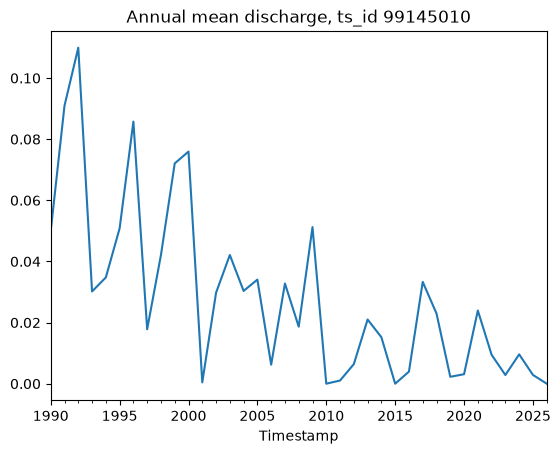

In [7]:
ts_id = long_records.iloc[0]["ts_id"]

values = kiwis(
    "getTimeseriesValues",
    ts_id=ts_id,
    **{"from": "1990-01-01", "to": "2026-10-01"},
    returnfields="Timestamp,Value,Quality Code",
)
v = values[0]
df = pd.DataFrame(v["data"], columns=v["columns"].split(","))
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df["Value"] = pd.to_numeric(df["Value"], errors="coerce")

print(df["Quality Code"].value_counts())
df.set_index("Timestamp")["Value"].resample("YE").mean().plot(
    title=f"Annual mean discharge, ts_id {ts_id}"
)

In [9]:
hrs_yes = ["609002","614224","612230","616178","605012","606195","607004","611111","613002"]

final = scores[scores["station_no"].astype(str).isin(hrs_yes)][
    ["station_no","station_name","basin","ts_id","share_A","share_missing"]].copy()
final["hrs_station"] = "Y"
final["notes"] = ""
final.loc[final["station_no"].astype(str) == "613002", "notes"] = \
    "HRS station; share_A 0.89, accepted below 0.90 threshold"
final.sort_values("basin").to_csv("stations.csv", index=False)
final

,station_no,station_name,basin,ts_id,share_A,share_missing,hrs_station,notes
2,605012,Mount Frankland,605,78933010,0.964605,0.000000,Y,
31,612230,James Crossing,612,95475010,0.977726,0.000053,Y,
39,613002,Dingo Rd,613,95921010,0.893180,0.000106,Y,"HRS station; share_A 0.89, accepted below 0.90..."
22,606195,Ordnance Rd Crossing,606,79419010,0.960954,0.000106,Y,
29,614224,Marradong Rd Bridge,614,102984010,0.980319,0.000159,Y,
36,609002,Brennans Ford,609,82501010,0.991694,0.000476,Y,
11,611111,Woodperry Homestead,611,92367010,0.923443,0.001058,Y,
55,607004,Quabicup Hill,607,79653010,0.951008,0.001905,Y,
20,616178,National Park,616,110423010,0.971166,0.002434,Y,
